# Task 4: Evaluate Robustness

Setup

In [33]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader, TensorDataset
from torchvision.transforms import v2 as T
from torchvision.transforms.v2 import functional as F

from cifar_data import CLASS_NAMES, get_split, load_cifar10, make_test_loader, prepare_inputs
from models.alexnet import AlexNet
from models.resnet import ResNet18
from train import CHECKPOINT_DIR, Run, count_parameters, evaluate, get_device, run_experiment

device = get_device()
NUM_WORKERS = 2 if device.type == "cuda" else 0

data = load_cifar10()
split = get_split(data["train"])
train_ids, val_ids, stats = split["train_ids"], split["val_ids"], split["stats"]
# loaders = make_loaders(run, data["train"], train_ids, val_ids)

print(f"train {len(split['train_ids'])} | val {len(split['val_ids'])} | test {len(data['test'])}")
print("torch", torch.__version__, "| device", device,"|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

train 45000 | val 5000 | test 10000
torch 2.11.0+cu128 | device cuda | NVIDIA GeForce RTX 4070


Train models (with and without augmentation)

In [34]:
EPOCHS = 15  # same budget as the Task 2 baselines
CONFIGS = {"alexnet": (AlexNet, 0.01), "resnet18": (ResNet18, 0.1)}

def train_or_load(model_class, run):
    path = CHECKPOINT_DIR / f"{run.name}_seed{run.seed}.pt"
    if path.exists():
        ckpt = torch.load(path, map_location=device)
        model = model_class(**run.options).to(device)
        model.load_state_dict(ckpt["state_dict"])
        return model, ckpt["history"], ckpt["summary"]
    return run_experiment(run, model_class, data, split, device, num_workers=NUM_WORKERS)

models, histories, summaries = {}, {}, {}
for arch, (model_class, lr) in CONFIGS.items():
    for aug in [False, True]:
        name = f"{arch}_{'aug' if aug else 'baseline'}"
        models[name], histories[name], summaries[name] = train_or_load(model_class, Run(name, epochs=EPOCHS, lr=lr, augmentation=aug))


Training curves

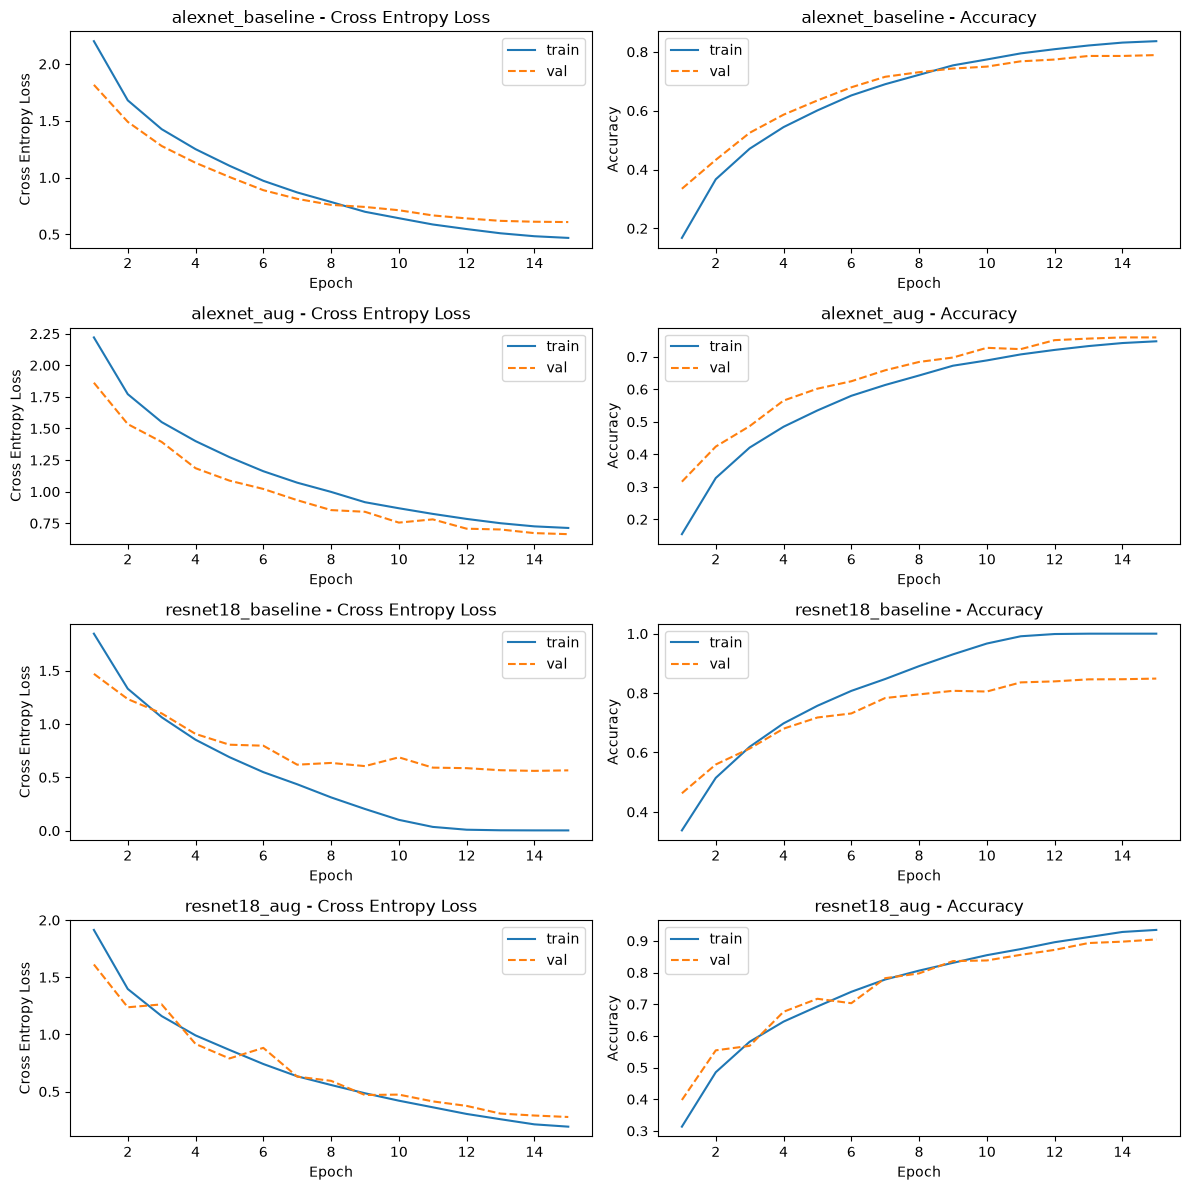

In [35]:
fig, axes = plt.subplots(len(histories), 2, figsize=(12, 3 * len(histories)))
for row, (name, h) in zip(axes, histories.items()):
    epochs = [r["epoch"] for r in h]
    for ax, metric, label in zip(row, ["ce", "accuracy"], ["Cross Entropy Loss", "Accuracy"]):
        ax.plot(epochs, [r[f"train_{metric}"] for r in h], label="train")
        ax.plot(epochs, [r[f"val_{metric}"] for r in h], "--", label="val")
        ax.set(title=f"{name} - {label}", xlabel="Epoch", ylabel=label); ax.legend()
plt.tight_layout(); plt.show()


Corrupted evaluation sets

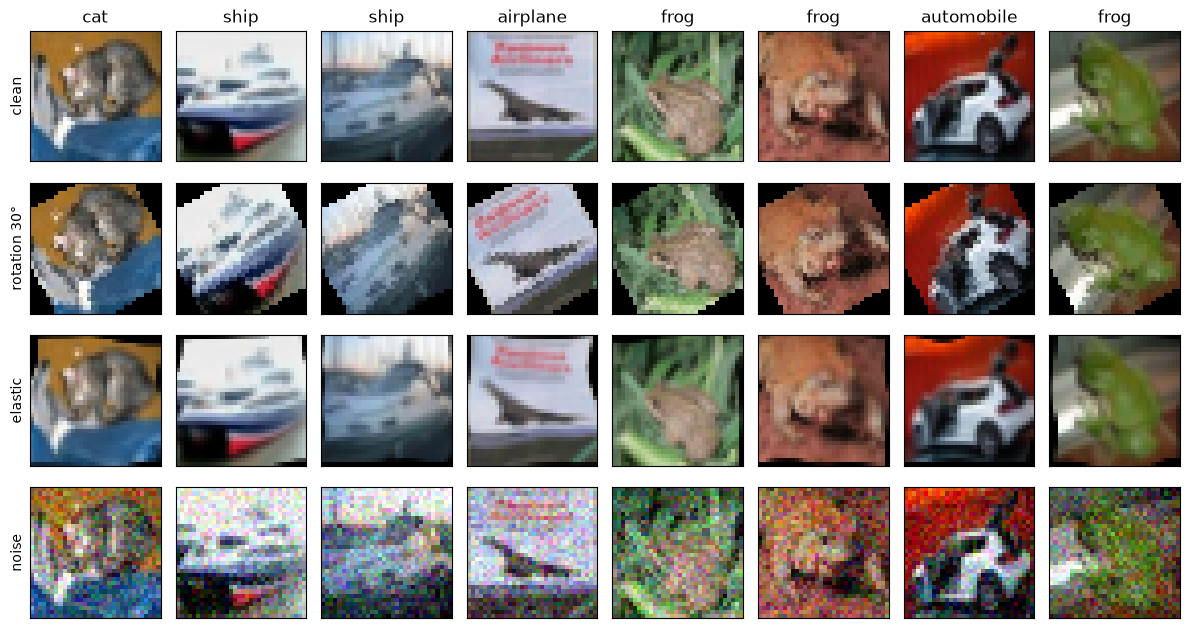

In [36]:
# fixed, seeded corrupted copies of the test set - same images and settings for every model
clean = torch.tensor(data["test"].data).permute(0, 3, 1, 2).float() / 255
labels = torch.tensor(data["test"].targets)

torch.manual_seed(0)  # elastic draws a random displacement field per image
elastic = T.ElasticTransform(alpha=30.0, sigma=4.0)
corrupted = {
    "clean": clean,
    "rotation 30°": F.rotate(clean, 30),
    "elastic": torch.stack([elastic(x) for x in clean]),
    "noise": (clean + 0.1 * torch.randn(clean.shape, generator=torch.Generator().manual_seed(0))).clamp(0, 1),
}

fig, axes = plt.subplots(len(corrupted), 8, figsize=(12, 6.5))
for r, (name, X) in enumerate(corrupted.items()):
    for c in range(8):
        ax = axes[r, c]
        ax.imshow(X[c].permute(1, 2, 0)); ax.set_xticks([]); ax.set_yticks([])
        if r == 0: ax.set_title(CLASS_NAMES[labels[c]])
        if c == 0: ax.set_ylabel(name)
plt.tight_layout(); plt.show()


Robustness evaluation

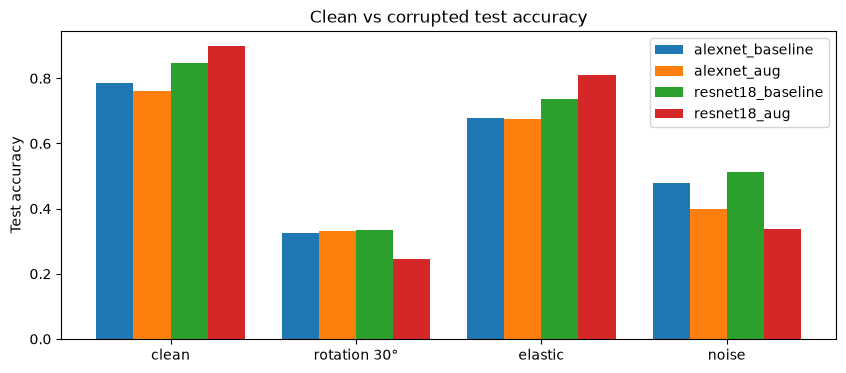

accuracy                                   ce               \
                     clean rotation 30° elastic   noise   clean rotation 30°   
alexnet_aug         0.7622       0.3314  0.6743  0.4004  0.6720       2.1689   
alexnet_baseline    0.7852       0.3243  0.6797  0.4796  0.6228       2.4158   
resnet18_aug        0.9005       0.2439  0.8092  0.3383  0.2907       3.8371   
resnet18_baseline   0.8481       0.3348  0.7353  0.5135  0.5779       3.2318   

                                   
                  elastic   noise  
alexnet_aug        0.9236  1.8183  
alexnet_baseline   0.9221  1.7270  
resnet18_aug       0.5871  2.7605  
resnet18_baseline  1.0421  2.2581

In [37]:
# evaluate every model on every set (same images for all) -> results[(model, set)] = {"ce", "accuracy"}
ids = torch.arange(len(labels))
results = {(m, s): evaluate(model, DataLoader(TensorDataset(X, labels, ids), batch_size=512), stats, device)
           for m, model in models.items() for s, X in corrupted.items()}

sets, x, w = list(corrupted), np.arange(len(corrupted)), 0.2
fig, ax = plt.subplots(figsize=(10, 4))
for i, m in enumerate(models):
    ax.bar(x + (i - 1.5) * w, [results[m, s]["accuracy"] for s in sets], w, label=m)
ax.set(xticks=x, xticklabels=sets, ylabel="Test accuracy", title="Clean vs corrupted test accuracy")
ax.legend(); plt.show()

# all 16 results as numbers: rows = model, columns = (metric, set)
display(pd.DataFrame(results).T.unstack()[["accuracy", "ce"]].reindex(columns=sets, level=1).round(4))


Per-class accuracy and computational cost

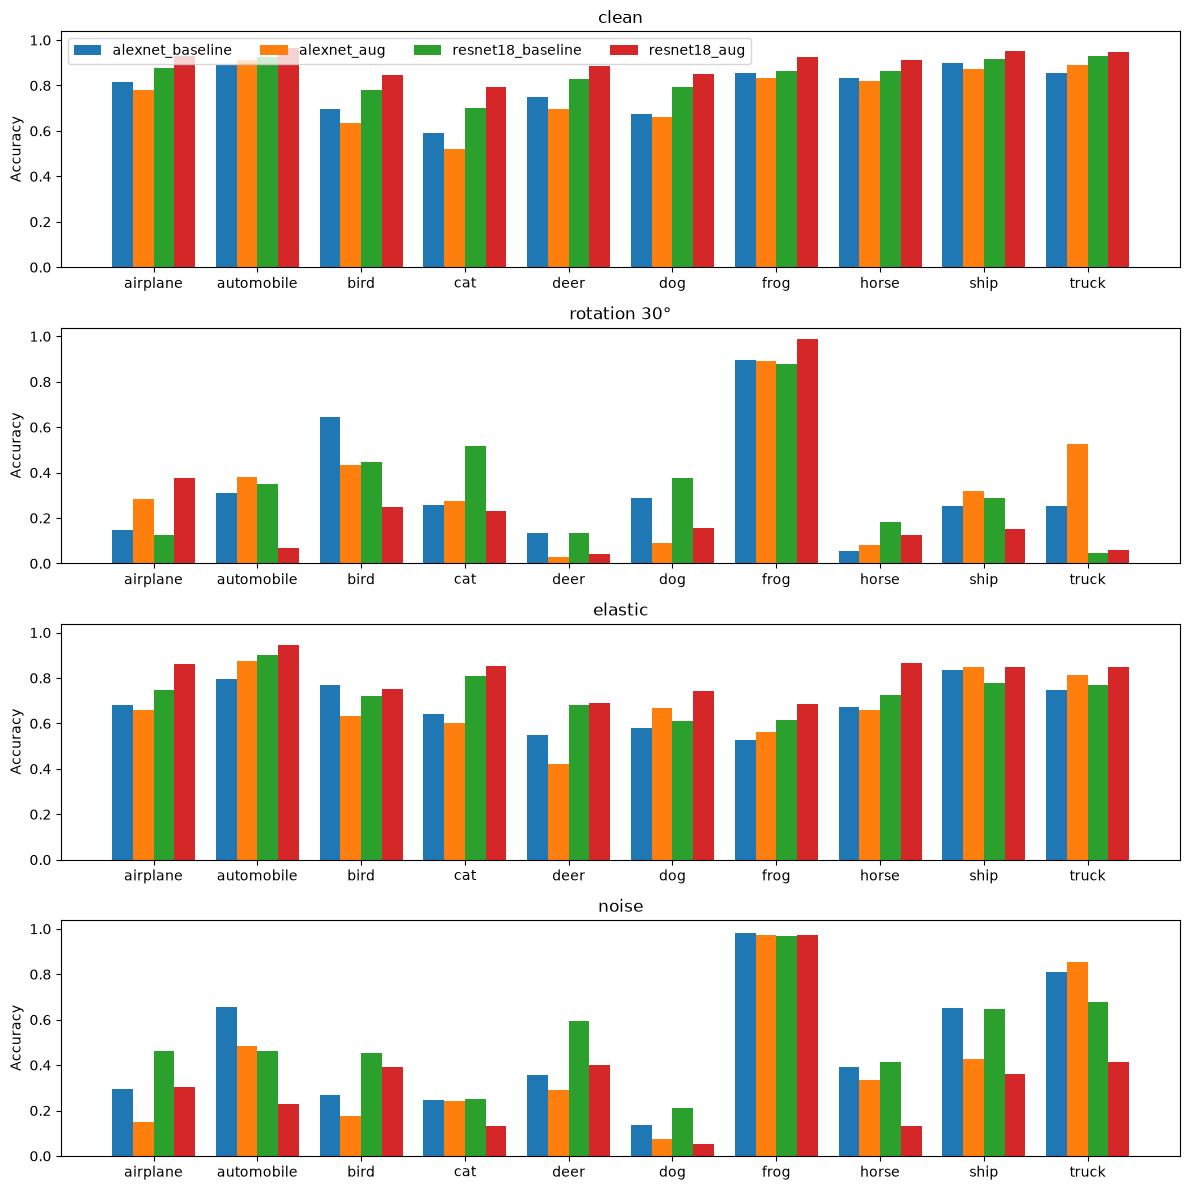

,parameters,train_s,train_s_per_epoch,eval_s_per_10k,peak_gpu_mb
alexnet_baseline,6976842.0,317.82,21.19,0.45,281.32
alexnet_aug,6976842.0,389.73,25.98,0.48,334.58
resnet18_baseline,11173962.0,507.01,33.80,1.70,870.76
resnet18_aug,11173962.0,515.91,34.39,1.63,956.44


In [38]:
@torch.inference_mode()
def predict(model, X, batch_size=512):
    model.eval()
    return torch.cat([model(prepare_inputs(X[i:i + batch_size].to(device), stats)).argmax(1).cpu()
                      for i in range(0, len(X), batch_size)])

preds, eval_seconds = {}, {}
for m, model in models.items():
    start = time.perf_counter()
    for s, X in corrupted.items():
        preds[m, s] = predict(model, X)
    eval_seconds[m] = (time.perf_counter() - start) / len(corrupted)  # seconds per 10k test images

x = np.arange(len(CLASS_NAMES))
fig, axes = plt.subplots(len(sets), 1, figsize=(12, 3 * len(sets)), sharey=True)
for ax, s in zip(axes, sets):
    for i, m in enumerate(models):
        acc = [(preds[m, s][labels == k] == k).float().mean().item() for k in range(len(CLASS_NAMES))]
        ax.bar(x + (i - 1.5) * w, acc, w, label=m)
    ax.set(xticks=x, xticklabels=CLASS_NAMES, ylabel="Accuracy", title=s)
axes[0].legend(ncol=4); plt.tight_layout(); plt.show()

display(pd.DataFrame({m: {
    "parameters": summaries[m]["parameters"],
    "train_s": summaries[m]["train_seconds"],
    "train_s_per_epoch": summaries[m]["train_seconds"] / EPOCHS,
    "eval_s_per_10k": eval_seconds[m],
    "peak_gpu_mb": summaries[m]["peak_gpu_mb"],
} for m in models}).T.round(2))


Error types per corruption

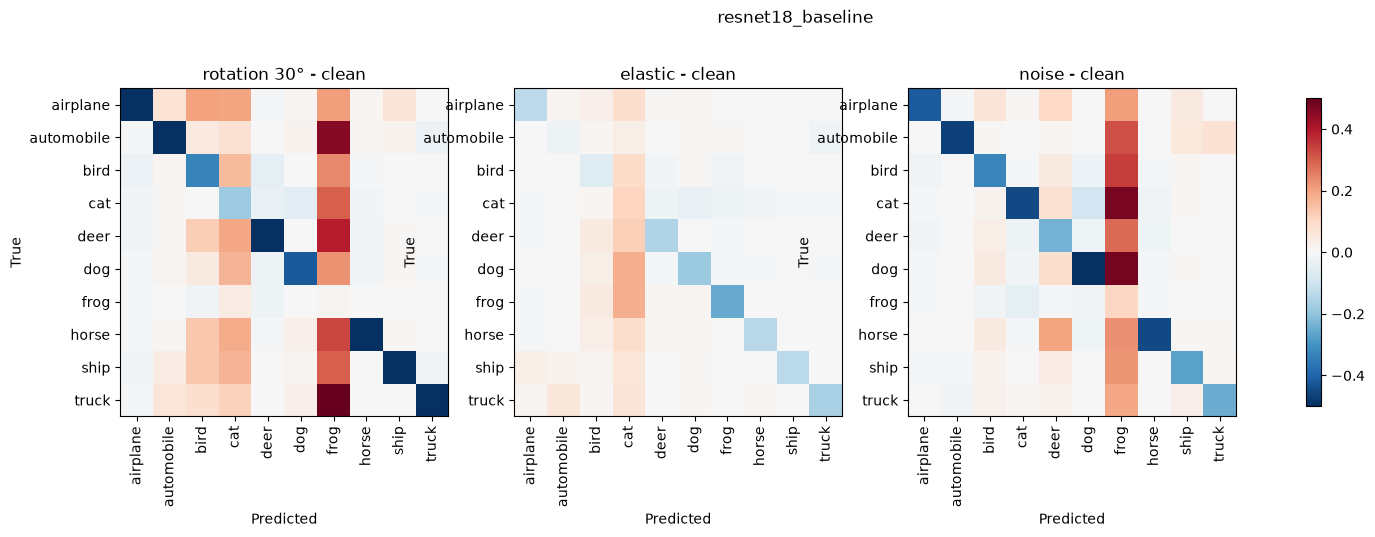

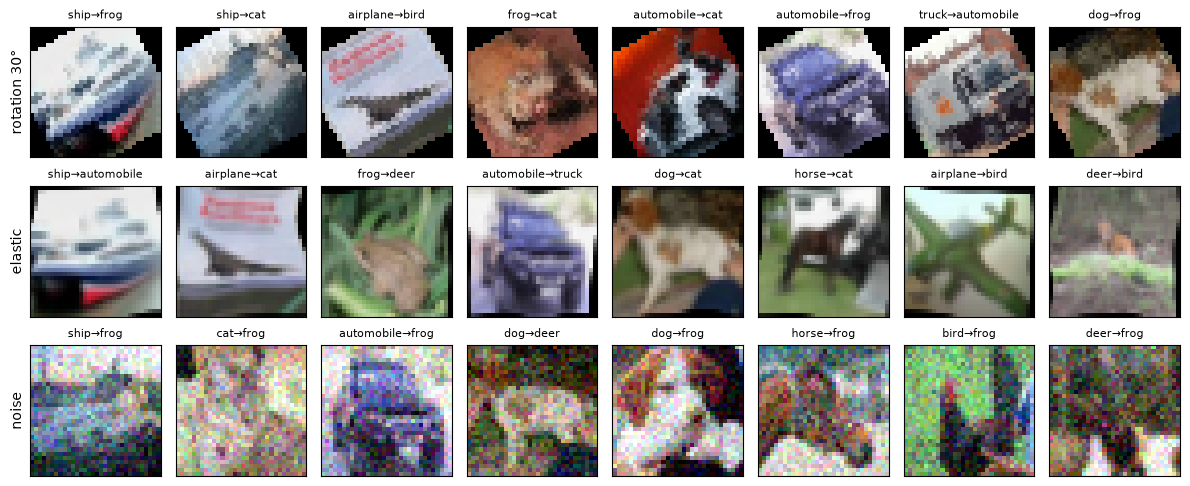

In [39]:
MODEL = "resnet18_baseline"  # which model to inspect

# confusion matrix of corrupted minus clean: red = confusions the corruption adds
clean_cm = confusion_matrix(labels, preds[MODEL, "clean"], normalize="true")
fig, axes = plt.subplots(1, len(sets) - 1, figsize=(18, 5))
for ax, s in zip(axes, sets[1:]):
    im = ax.imshow(confusion_matrix(labels, preds[MODEL, s], normalize="true") - clean_cm, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
    ax.set(title=f"{s} - clean", xticks=range(10), yticks=range(10), xlabel="Predicted", ylabel="True")
    ax.set_xticklabels(CLASS_NAMES, rotation=90); ax.set_yticklabels(CLASS_NAMES)
fig.colorbar(im, ax=axes, shrink=0.8); fig.suptitle(MODEL); plt.show()

# images the corruption broke (correct on clean, wrong when corrupted): true -> predicted
fig, axes = plt.subplots(len(sets) - 1, 8, figsize=(12, 5))
for row, s in zip(axes, sets[1:]):
    broken = ((preds[MODEL, s] != labels) & (preds[MODEL, "clean"] == labels)).nonzero().flatten()[:8]
    for ax, i in zip(row, broken):
        ax.imshow(corrupted[s][i].permute(1, 2, 0)); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{CLASS_NAMES[labels[i]]}→{CLASS_NAMES[preds[MODEL, s][i]]}", fontsize=8)
    row[0].set_ylabel(s)
plt.tight_layout(); plt.show()
